# Global Equity Differences (working draft)

In this notebook we'll look at extending the model beyond a *US perspective*. The historical model is driven by using returns differential of US foreign and US investor. US investors or investors who park their money in the US likely account for a large proportion of international flow, but there may be some residual from external investors. This notebook will examine that and for now use a group of liquid FX futures. 

## Packages

In [114]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Getting Data

In [15]:
path        = r"A:\GitHub\FXEquitySpillover\data\PrepData\FXVolTargetedReturns.parquet"
tickers     = ["EC", "JY", "AD"]
tmp_tickers = ["{}1 Curncy".format(ticker) for ticker in tickers]

df_fx = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.vol_target == "perfect"]
    .loc[lambda x: x.security.isin(tmp_tickers)])

In [21]:
path      = r"A:\GitHub\FXEquitySpillover\data\FXTickerGuide.xlsx"
df_ticker = (pd
    .read_excel(io = path, sheet_name = "TickerGuide")
    .loc[lambda x: x.etf_ticker == x.etf_ticker]
    [["ticker", "name", "country", "etf_ticker"]])

In [104]:
path           = r"A:\GitHub\FXEquitySpillover\data\PrepData\ETFReturns.parquet"
df_raw_etf_rtn = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .dropna())

In [108]:
keep_tickers = (df_raw_etf_rtn
    .dropna()
    [["date", "ticker"]]
    .groupby("ticker")
    .agg("min")
    .sort_values("date")
    .assign(year = lambda x: x.date.dt.year)
    .loc[lambda x: x.year <= 2009]
    .index
    .to_list())

df_etf_rtn = (df_raw_etf_rtn
    .loc[lambda x: x.ticker.isin(keep_tickers)])

In [109]:
tickers  = df_fx.security.drop_duplicates().sort_values().to_list()
df_lists = []

for ticker in tickers: 

    ticker_dict = (df_ticker
        [["ticker", "etf_ticker"]]
        .assign(etf_ticker = lambda x: x.etf_ticker.str.split(" ").str[0])
        .set_index("ticker")
        .etf_ticker
        .to_dict())

    etf_name      = ticker_dict[ticker]
    other_tickers = (df_ticker
        .loc[lambda x: x.etf_ticker != etf_name]
        .assign(etf_ticker = lambda x: x.etf_ticker.str.split(" ").str[0])
        .etf_ticker
        .drop_duplicates()
        .to_list())

    all_tickers = other_tickers + [etf_name, "SPY"]
    df_add      = (df_etf_rtn
        .loc[lambda x: x.ticker.isin(all_tickers)]
        .pivot(index = "date", columns = "ticker", values = "rtn")
        .reset_index()
        .melt(id_vars = ["date", etf_name])
        .dropna()
        .rename(columns = {etf_name: "sov_rtn"})
        .assign(
            sov_etf    = etf_name,
            spread_rtn = lambda x: x.sov_rtn - x.value)
        .rename(columns = {"ticker": "for_etf"}))

    df_lists.append(df_add)

df_spread = pd.concat(df_lists)

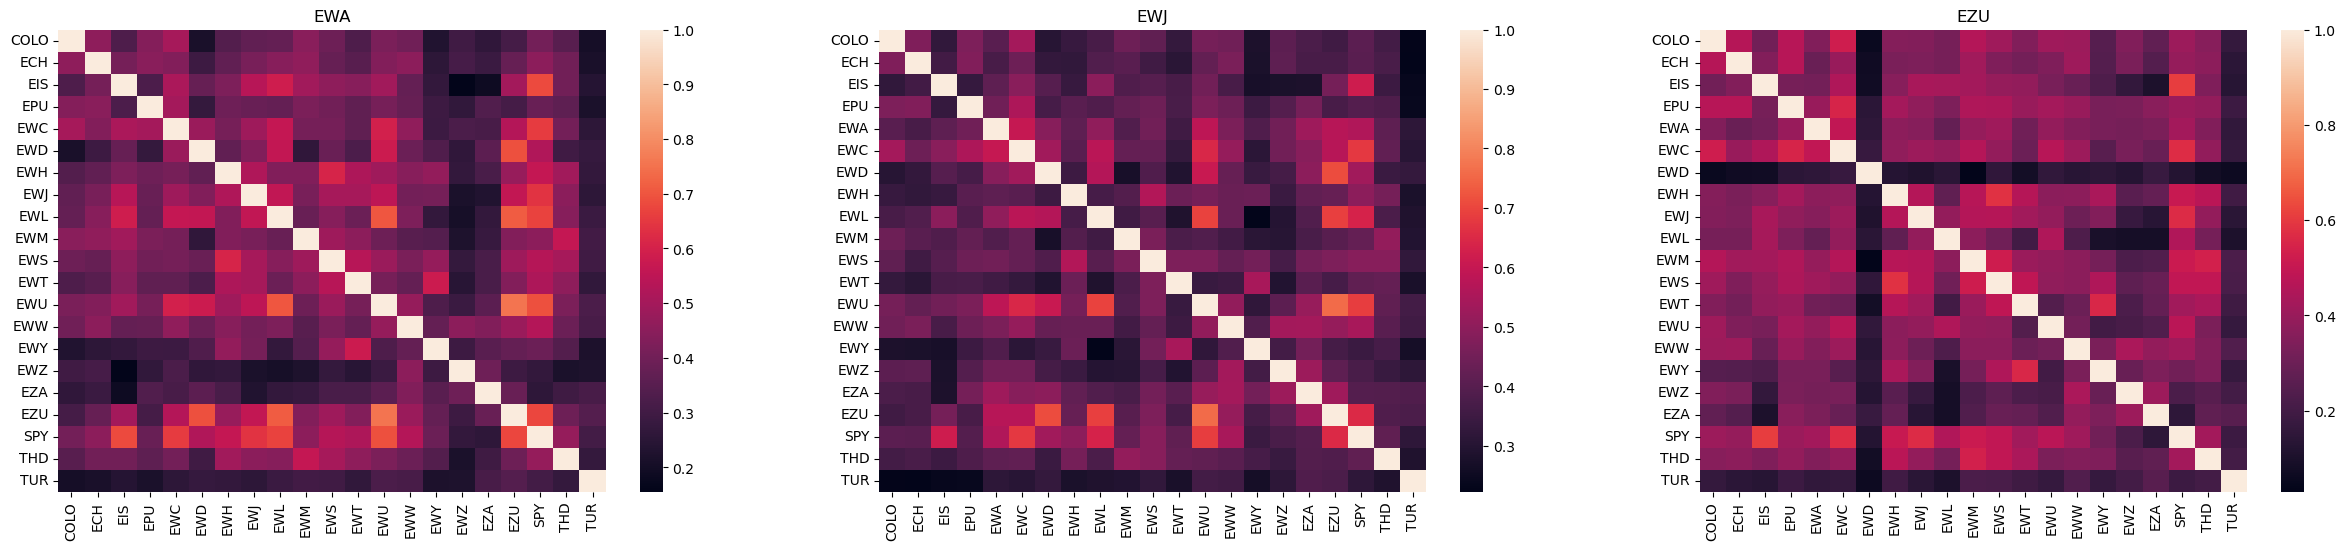

In [119]:
tickers   = df_spread.sov_etf.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(tickers), figsize = (30,6))

for ticker, ax in zip(tickers, axes.flatten()): 

    df_corr = (df_spread
        .loc[lambda x: x.sov_etf == ticker]
        .pivot(index = "date", columns = "for_etf", values = "spread_rtn")
        .corr())

    sns.heatmap(
        ax    = ax,
        data  = df_corr)

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(ticker)

fig.suptitle("Correlation of Returns Differential Controlling for S")